# Semana 15: PCA y actividad poblacional

**Objetivo:** reducir la actividad de muchas neuronas a pocas dimensiones y comprobar si esas
dimensiones recuperan la estructura que generó los datos.

## Modelo generativo

Seis neuronas comparten una variable latente $z$ que depende de la condición experimental
$c \in \{0, 1, 2\}$:

$$z = c + \eta, \quad \eta \sim \mathcal{N}(0, 0.3^2); \qquad \mathbf{r} = z\,\mathbf{w} + \boldsymbol\epsilon, \quad \boldsymbol\epsilon \sim \mathcal{N}(0, 0.25^2 I)$$

Es decir, la actividad vive casi en **una** dimensión (la dirección $\mathbf{w}$) más ruido independiente.

## PCA

Con los datos centrados $X$, PCA busca las direcciones de máxima varianza: los autovectores de la
covarianza $C = \frac{1}{n-1}X^\top X$. La fracción de varianza explicada por el componente $k$ es
$\lambda_k / \sum_j \lambda_j$.

**Predicción:** PC1 debe explicar casi toda la varianza, alinearse con $\mathbf{w}$ y ordenar las
condiciones 0 < 1 < 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import fit_pca
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 15
NEURONS = 6
rng = np.random.default_rng(15)
conditions = np.repeat(np.arange(3), 80)
latent = conditions.astype(float) + rng.normal(0.0, 0.3, conditions.size)
loadings = rng.normal(size=NEURONS)
activity = latent[:, None] * loadings[None, :] + rng.normal(0.0, 0.25, (conditions.size, NEURONS))
pca_all = fit_pca(activity, n_components=NEURONS)
scores = pca_all.transform(activity)[:, :2]

## Figura

Izquierda: proyección en PC1-PC2 coloreada por condición. Derecha: varianza explicada por cada
componente (*scree plot*).

Saved: weeks/week_15_population_pca/outputs/population_pca.png
Saved: weeks/week_15_population_pca/outputs/population_pca.npz


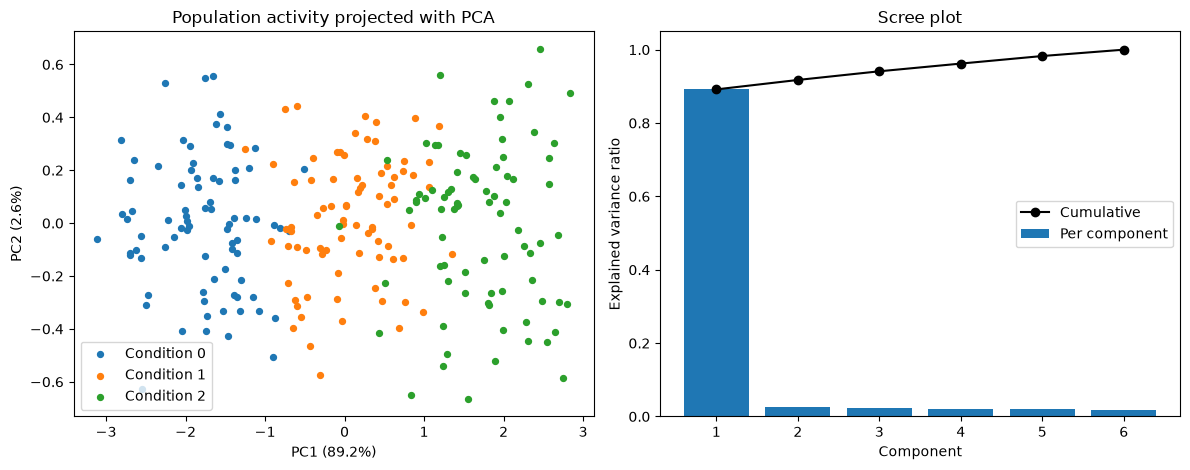

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for condition in np.unique(conditions):
    mask = conditions == condition
    axes[0].scatter(scores[mask, 0], scores[mask, 1], s=18, label=f"Condition {condition}")
ratio = pca_all.explained_variance_ratio
axes[0].set(xlabel=f"PC1 ({ratio[0]:.1%})", ylabel=f"PC2 ({ratio[1]:.1%})", title="Population activity projected with PCA")
axes[0].legend()
axes[1].bar(np.arange(1, NEURONS + 1), ratio, label="Per component")
axes[1].plot(np.arange(1, NEURONS + 1), np.cumsum(ratio), "ko-", label="Cumulative")
axes[1].set(xlabel="Component", ylabel="Explained variance ratio", ylim=(0, 1.05), title="Scree plot")
axes[1].legend()
save_figure(WEEK, figure, "population_pca.png")
save_data(WEEK, "population_pca.npz", activity=activity, condition=conditions, scores=scores,
          explained_variance_ratio=ratio, true_loadings=loadings)

## Validación

- PC1 explica más del 80 % de la varianza (estructura de una dimensión).
- PC1 está alineado con las cargas verdaderas: $|\cos\theta| > 0.95$ (el signo de un componente
  es arbitrario).
- Las medias por condición sobre PC1 están ordenadas (de forma creciente o decreciente).
- Las proporciones de varianza suman 1.

In [3]:
cosine = abs(pca_all.components[0] @ loadings) / np.linalg.norm(loadings)
condition_means = np.array([scores[conditions == c, 0].mean() for c in range(3)])
assert ratio[0] > 0.8
assert cosine > 0.95, cosine
assert np.all(np.diff(condition_means) > 0) or np.all(np.diff(condition_means) < 0)
assert abs(ratio.sum() - 1.0) < 1e-9
print(f"PC1 explains {ratio[0]:.1%}; |cos(PC1, true loadings)| = {cosine:.3f}")
print(f"Condition means on PC1: {np.round(condition_means, 2)}")

PC1 explains 89.2%; |cos(PC1, true loadings)| = 1.000
Condition means on PC1: [-1.79  0.07  1.71]


## Interpretación y límites

- PCA recupera la dirección latente porque aquí la señal tiene mucha más varianza que el ruido.
  Si el ruido fuera mayor o correlacionado, PC1 podría capturar ruido en vez de la variable de interés.
- Los componentes son direcciones de varianza, no necesariamente "variables" con significado
  biológico; PC2 aquí es solo ruido.

**Para tu entrega:** sube el ruido de 0.25 a 1.0 y reporta cómo cambian la varianza explicada y
el coseno con las cargas verdaderas.